#### Importation des modules et du dataset d'entrainement

In [ ]:
# Importation des modules
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

In [8]:
# Importation du dataset d'entrainement
train = pd.read_csv("../data/Train.csv")

Description des variables

| Variable | Description |
|---|---|
| `ID` | Identifiant unique du client |
| `Gender` | Genre du client |
| `Ever_Married` | État civil du client |
| `Age` | Âge du client |
| `Graduated` | Indique si le client est diplômé |
| `Profession` | Profession du client |
| `Work_Experience` | Expérience professionnelle (en années) |
| `Spending_Score` | Score de dépenses du client |
| `Family_Size` | Nombre de membres dans la famille (client inclus) |
| `Var_1` | Catégorie anonymisée du client |
| `Segmentation` | Segment cible du client *(variable à prédire)* |

In [19]:
# print(train.head())
print(train.info())

<class 'pandas.DataFrame'>
RangeIndex: 8068 entries, 0 to 8067
Data columns (total 11 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   ID               8068 non-null   int64  
 1   Gender           8068 non-null   str    
 2   Ever_Married     7928 non-null   str    
 3   Age              8068 non-null   int64  
 4   Graduated        7990 non-null   str    
 5   Profession       7944 non-null   str    
 6   Work_Experience  7239 non-null   float64
 7   Spending_Score   8068 non-null   str    
 8   Family_Size      7733 non-null   float64
 9   Var_1            7992 non-null   str    
 10  Segmentation     8068 non-null   str    
dtypes: float64(2), int64(2), str(7)
memory usage: 693.5 KB
None


In [20]:
num_vars = ['Age', 'Work_Experience', 'Family_Size']
cat_vars = ['Gender', 'Ever_Married', 'Graduated', 'Profession', 'Spending_Score', 'Var_1']
target = ['Segmentation']

##### Analyse Univariée

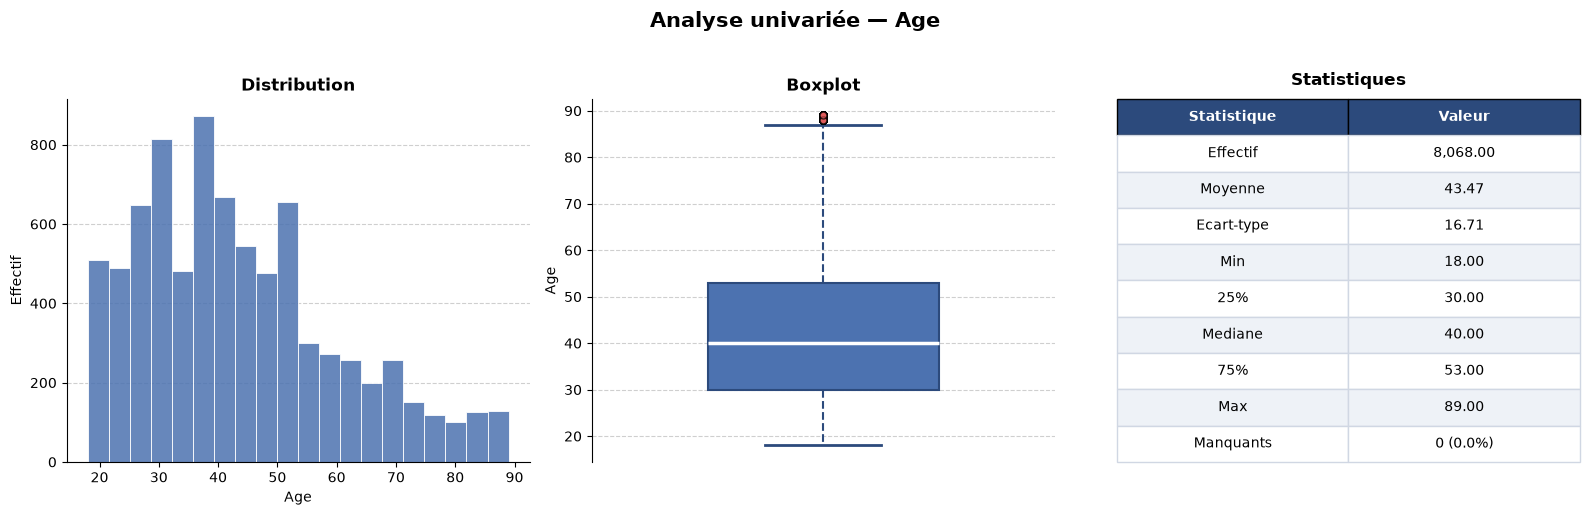

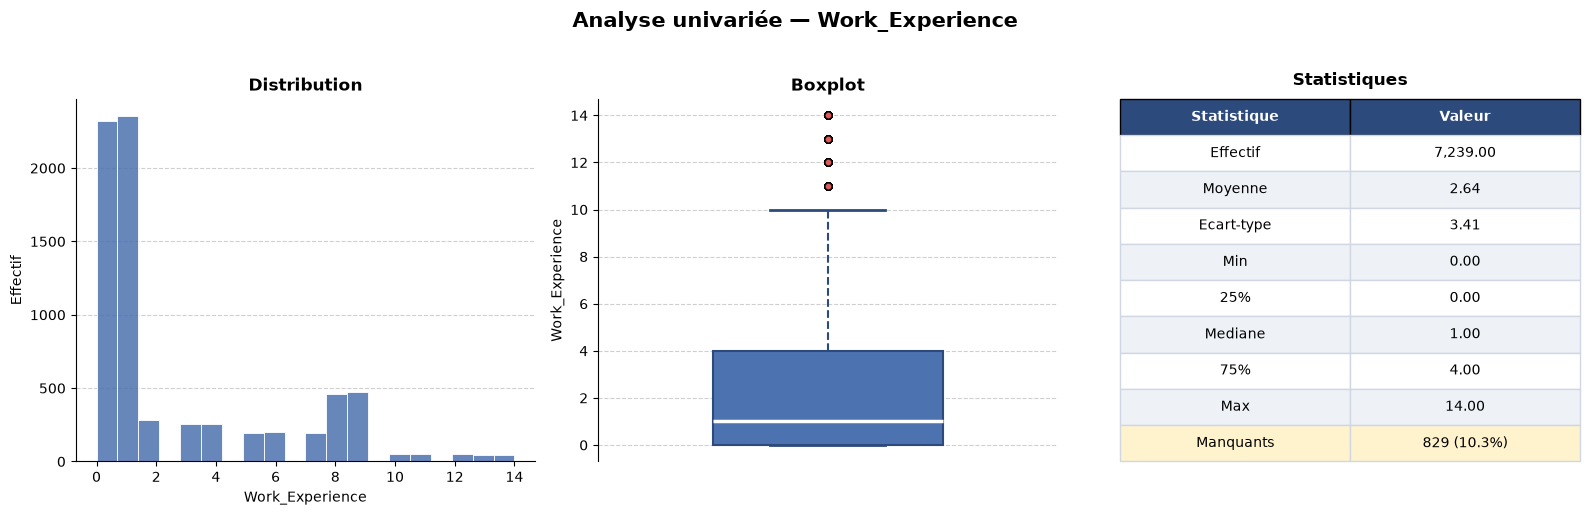

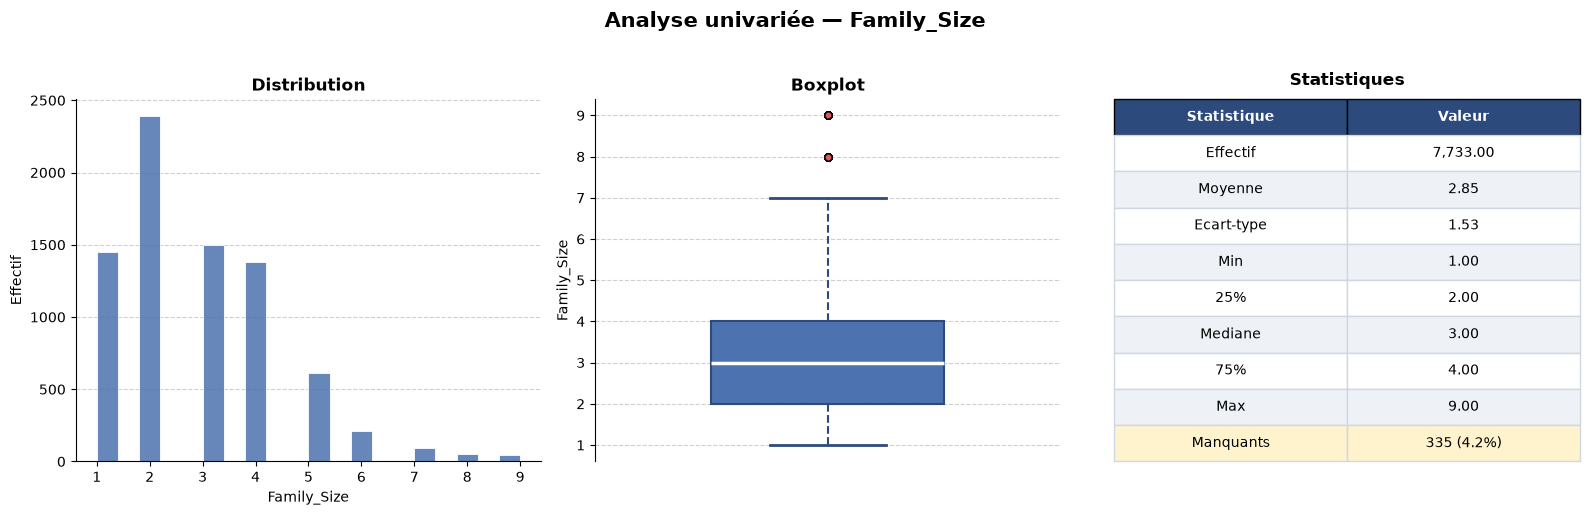

In [ ]:
## Analyse Univariée des variables quantitatives

warnings.filterwarnings('ignore')

for col in num_vars:
    fig, axes = plt.subplots(1, 3, figsize=(16, 5))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    color_main = '#4C72B0'
    color_dark  = '#2c4a7c'

    # --- Histogramme ---
    ax = axes[0]
    ax.hist(train[col].dropna(), bins=20, color=color_main,
            edgecolor='white', linewidth=0.7, alpha=0.85)

    ax.set_title('Distribution', fontsize=12, fontweight='bold')
    ax.set_xlabel(col, fontsize=10)
    ax.set_ylabel('Effectif', fontsize=10)
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)

    # --- Boxplot ---
    ax = axes[1]
    bp = ax.boxplot(train[col].dropna(), patch_artist=True, orientation='vertical',
                    widths=0.5,
                    boxprops=dict(facecolor=color_main, color=color_dark, linewidth=1.5),
                    medianprops=dict(color='white', linewidth=2.5),
                    whiskerprops=dict(color=color_dark, linewidth=1.5, linestyle='--'),
                    capprops=dict(color=color_dark, linewidth=2),
                    flierprops=dict(marker='o', color=color_dark,
                                   markerfacecolor='#e05c5c', markersize=5, alpha=0.7))

    ax.set_title('Boxplot', fontsize=12, fontweight='bold')
    ax.set_ylabel(col, fontsize=10)
    ax.set_xticks([])
    ax.grid(axis='y', linestyle='--', alpha=0.6)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right', 'bottom']].set_visible(False)

    # --- Stats descriptives ---
    ax = axes[2]
    ax.axis('off')

    stats = train[col].describe().round(2)
    missing = train[col].isnull().sum()
    missing_pct = train[col].isnull().mean() * 100

    labels = {
        'count': 'Effectif', 'mean': 'Moyenne', 'std': 'Ecart-type',
        'min': 'Min', '25%': '25%', '50%': 'Mediane',
        '75%': '75%', 'max': 'Max'
    }

    table_data = [[labels.get(k, k), f"{v:,.2f}"] for k, v in stats.items()]
    table_data.append(['Manquants', f"{missing} ({missing_pct:.1f}%)"])

    table = ax.table(
        cellText=table_data,
        colLabels=['Statistique', 'Valeur'],
        loc='center', cellLoc='center',
        bbox=[0, 0, 1, 1]
    )
    table.auto_set_font_size(False)
    table.set_fontsize(10)

    for j in range(2):
        table[0, j].set_facecolor(color_dark)
        table[0, j].set_text_props(color='white', fontweight='bold')

    for i in range(1, len(table_data) + 1):
        for j in range(2):
            table[i, j].set_facecolor('#eef2f7' if i % 2 == 0 else 'white')
            table[i, j].set_edgecolor('#d0d7e3')

    if missing > 0:
        for j in range(2):
            table[len(table_data), j].set_facecolor('#fff3cd')

    ax.set_title('Statistiques', fontsize=12, fontweight='bold', pad=10)

    plt.tight_layout()
    plt.show()

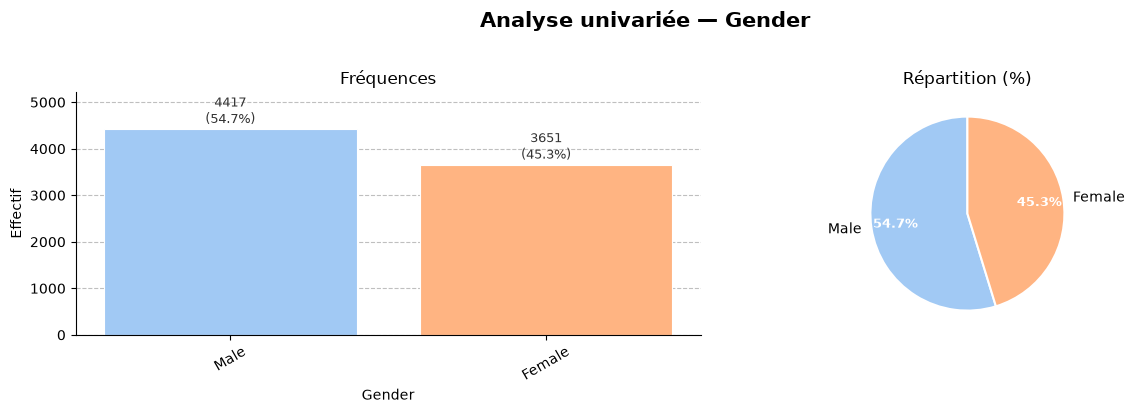

→ Modalités : 2
→ Valeurs manquantes : 0 (0.0%)


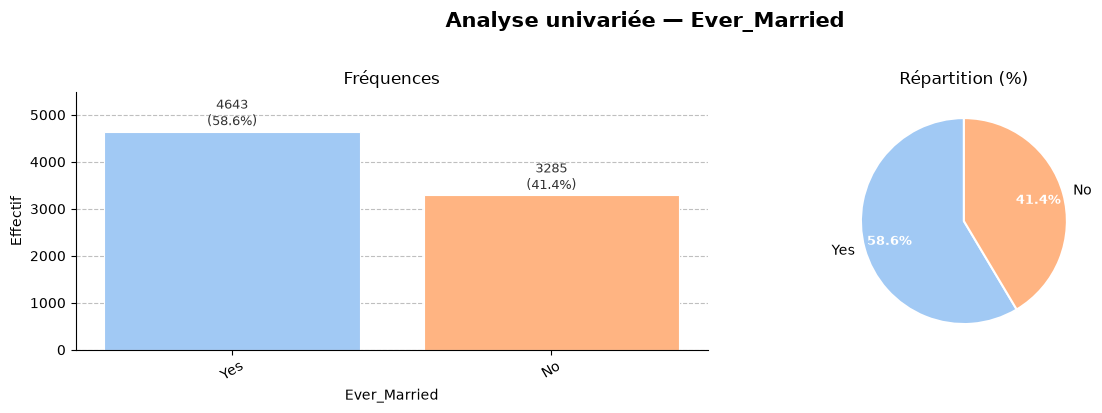

→ Modalités : 2
→ Valeurs manquantes : 140 (1.7%)


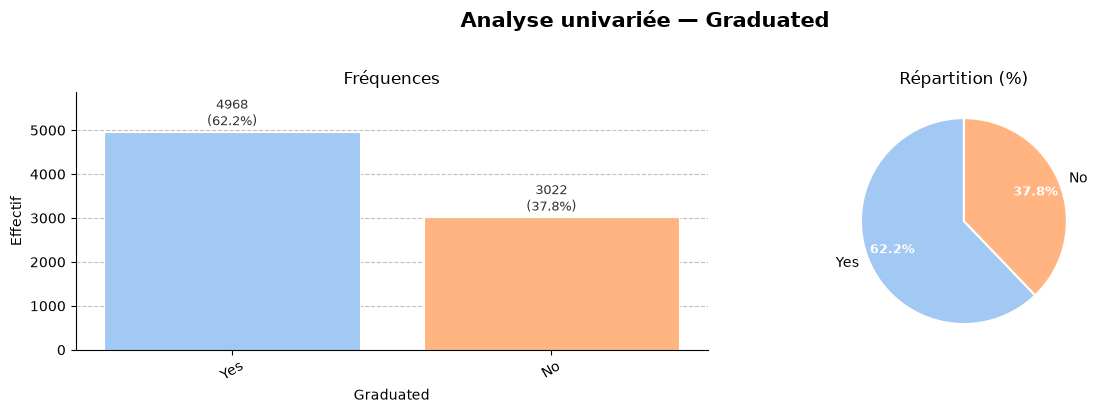

→ Modalités : 2
→ Valeurs manquantes : 78 (1.0%)


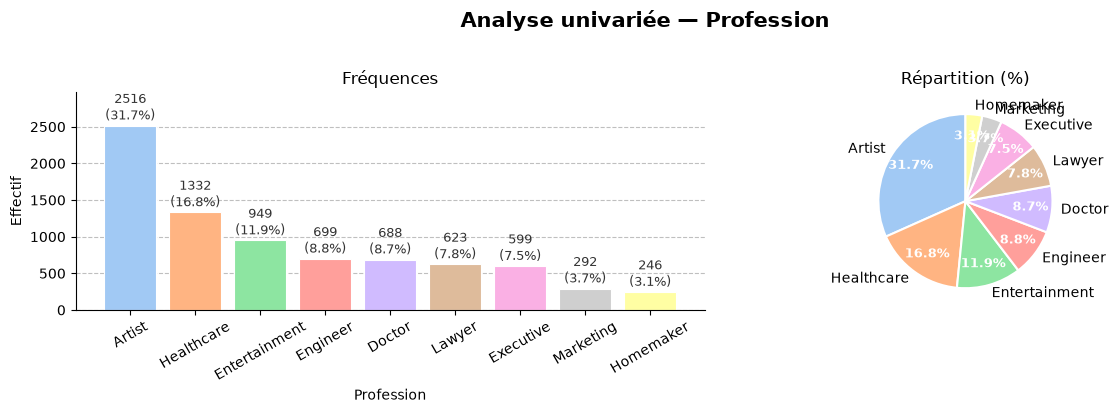

→ Modalités : 9
→ Valeurs manquantes : 124 (1.5%)


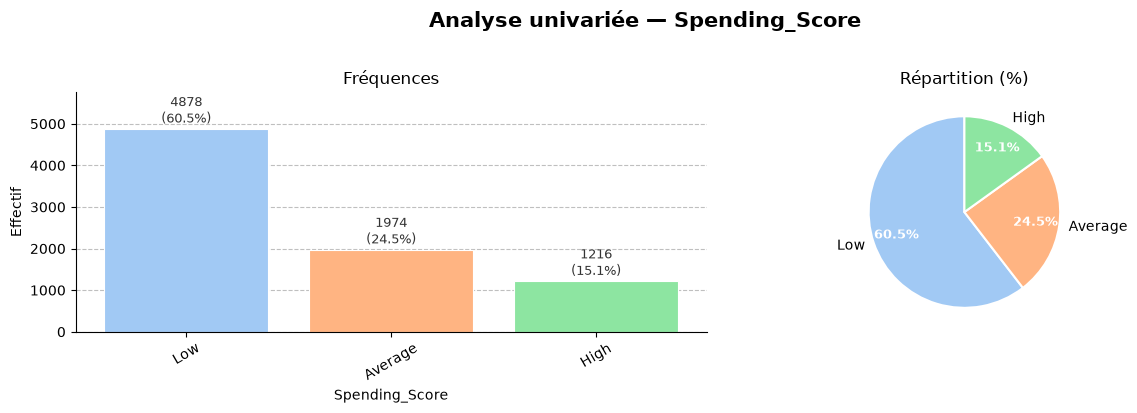

→ Modalités : 3
→ Valeurs manquantes : 0 (0.0%)


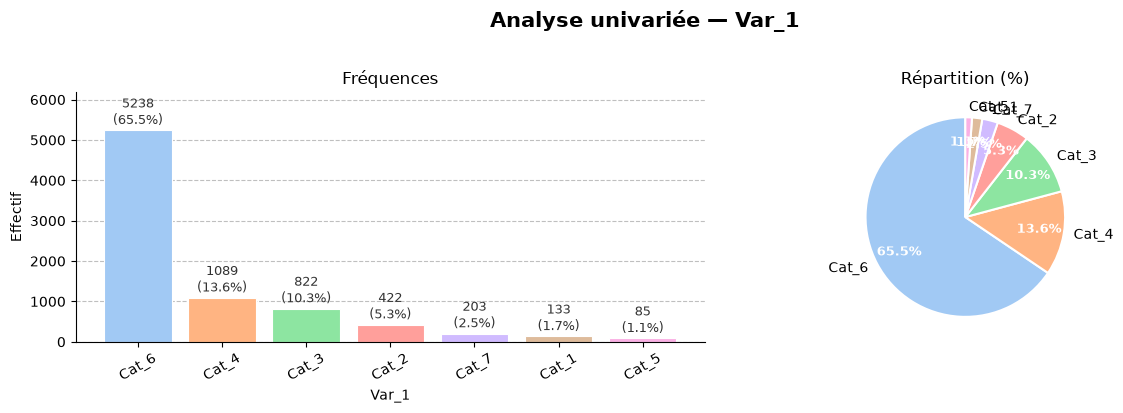

→ Modalités : 7
→ Valeurs manquantes : 76 (0.9%)


In [30]:
## Analyse Univariée des variables catégorielles

for col in cat_vars:
    counts = train[col].value_counts()
    pcts = train[col].value_counts(normalize=True) * 100
    n = len(counts)

    # Palette dynamique selon le nombre de modalités
    palette = sns.color_palette("pastel", n)

    fig, axes = plt.subplots(1, 2, figsize=(13, 4))
    fig.suptitle(f'Analyse univariée — {col}', fontsize=15, fontweight='bold', y=1.02)

    # --- Bar chart ---
    bars = axes[0].bar(counts.index.astype(str), counts.values,
                       color=palette, edgecolor='white', linewidth=0.8)

    # Annotations au-dessus des barres
    for bar, val, pct in zip(bars, counts.values, pcts.values):
        axes[0].text(bar.get_x() + bar.get_width() / 2,
                     bar.get_height() + max(counts.values) * 0.01,
                     f'{val}\n({pct:.1f}%)',
                     ha='center', va='bottom', fontsize=9, color='#333333')

    axes[0].set_title('Fréquences', fontsize=12)
    axes[0].set_xlabel(col, fontsize=10)
    axes[0].set_ylabel('Effectif', fontsize=10)
    axes[0].tick_params(axis='x', rotation=30)
    axes[0].set_ylim(0, max(counts.values) * 1.18)
    axes[0].grid(axis='y', linestyle='--', alpha=0.5, color='gray')
    axes[0].set_axisbelow(True)
    axes[0].spines[['top', 'right']].set_visible(False)

    # --- Pie chart ---
    wedges, texts, autotexts = axes[1].pie(
        counts.values,
        labels=counts.index.astype(str),
        autopct='%1.1f%%',
        startangle=90,
        colors=palette,
        wedgeprops=dict(edgecolor='white', linewidth=1.5),
        pctdistance=0.75
    )
    for at in autotexts:
        at.set_fontsize(9)
        at.set_color('white')
        at.set_fontweight('bold')
    axes[1].set_title('Répartition (%)', fontsize=12)

    plt.tight_layout()
    plt.show()

    # Résumé texte
    print(f"→ Modalités : {train[col].nunique()}")
    print(f"→ Valeurs manquantes : {train[col].isnull().sum()} ({train[col].isnull().mean()*100:.1f}%)")
    # print(pd.DataFrame({'Effectif': counts, 'Pourcentage (%)': pcts.round(1)}), '\n')

In [15]:
train['Var_1'].unique()

<StringArray>
['Cat_4', 'Cat_6', 'Cat_7', 'Cat_3', 'Cat_1', 'Cat_2', nan, 'Cat_5']
Length: 8, dtype: str